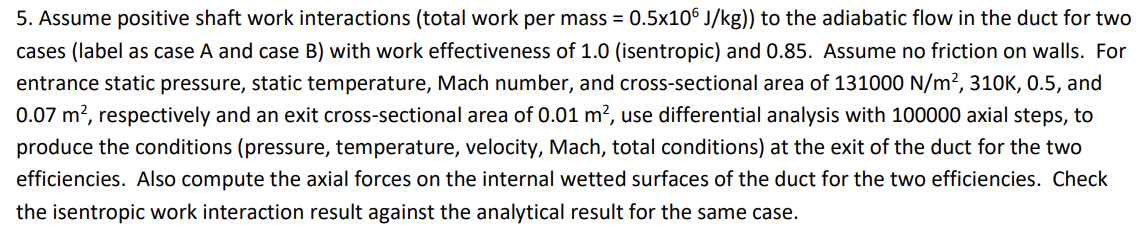

In [1]:
import numpy as np
from quasi_1D import quasi_1D_flow
import matplotlib.pyplot as plt

import scipy as sp


In [2]:
Cp = 1004.5
R = 287
gamma = 1.4

# Numerical

In [3]:
Pi = 131_000
Ti = 310
Mi = 0.5
ui = Mi * np.sqrt(1.4*287*Ti)


w = 0.5e+6
eta = 1

L_tube = 1
axial_steps = 100_000

Ai = 0.07
Ae = 0.01

xlist = np.linspace(0,L_tube,axial_steps+1)
Af = lambda x: (Ae - Ai) * x + Ai


[uout,Tout,Pout], M, x_break, A_break, Thrust = quasi_1D_flow(inlet = [ui,Ti,Pi], Af = Af,N = axial_steps, L = L_tube, w = w, eta= eta)

0


In [4]:
gamma = 1.4
Tt = Tout*(1+(gamma-1)/2*M**2)
Pt = Pout*(1+(gamma-1)/2*M**2)**(gamma/(gamma-1))


print(f'exit Mach =             {M[-1]}')
print(f'exit Velocity =         {uout[-1]} m/s\n')

print(f'exit Temp =             {Tout[-1]} k')
print(f'exit Total Temp =       {Tt[-1]} k\n')

print(f'exit Pressure =         {Pout[-1]} Pa')
print(f'exit Total Pressure =   {Pt[-1]} Pa\n')

# print(f'exit end area = {A_break}')
print(f'{Thrust =                } N')


exit Mach =             0.19096866170899848
exit Velocity =         109.43533772364584 m/s

exit Temp =             817.2991050981792 k
exit Total Temp =       823.2603261746792 k

exit Pressure =         3898002.020918151 Pa
exit Total Pressure =   3998422.0320154317 Pa

Thrust =                28590.76139578894 N


# Analytical

In [5]:
Tti = Tt[0]
Pti = Pt[0]

Tte = w/Cp + Tti
Pte = Pti * (Tte/Tti)**(gamma/(gamma-1))

m_dot = lambda M: Pte/np.sqrt(R*Tte) * M*(1+(gamma-1)/2*M**2)**(1/2)/(1+(gamma-1)/2*M**2)**(gamma/(gamma-1)) * np.sqrt(gamma)* Ae
func = lambda M: m_dot(M) - Pi/(R*Ti) * ui * Ai

Me = sp.optimize.fsolve(func,.19)[0]

Te = Tte/(1+(gamma-1)/2*Me**2)
Pe = Pte/(1+(gamma-1)/2*Me**2)**(gamma/(gamma-1))
rho0 = Pi/(R*Ti)
rho = Pe / (R*Te)
ue = Me * np.sqrt(gamma*R*Te)
Thrust_a = (rho*ue**2+Pe)*Ae - (rho0*ui**2+Pi)*Ai

# Numerical

In [6]:
Pi = 131_000
Ti = 310
Mi = 0.5
ui = Mi * np.sqrt(1.4*287*Ti)

w = 0.5e+6
eta = 0.85

L_tube = 1
axial_steps = 200_0000

Ai = 0.07
Ae = 0.01

xlist = np.linspace(0,L_tube,axial_steps+1)
Af = lambda x: (Ae - Ai) * x + Ai

[uout,Tout,Pout], M, x_break, A_break, Thrust = quasi_1D_flow(inlet = [ui,Ti,Pi], Af = Af,N = axial_steps, L = L_tube, w = w, eta= eta)

0


In [7]:
gamma = 1.4
Tt = Tout*(1+(gamma-1)/2*M**2)
Pt = Pout*(1+(gamma-1)/2*M**2)**(gamma/(gamma-1))


print(f'exit Mach =             {M[-1]}')
print(f'exit Velocity =         {uout[-1]} m/s\n')

print(f'exit Temp =             {Tout[-1]} k')
print(f'exit Total Temp =       {Tt[-1]} k\n')

print(f'exit Pressure =         {Pout[-1]} Pa')
print(f'exit Total Pressure =   {Pt[-1]} Pa\n')

# print(f'exit end area = {A_break}')
print(f'{Thrust =                } N')


exit Mach =             0.3264094466395533
exit Velocity =         185.7623593173812 m/s

exit Temp =             806.0835635058327 k
exit Total Temp =       823.2600961783861 k

exit Pressure =         2265082.489880405 Pa
exit Total Pressure =   2438560.4271375467 Pa

Thrust =                13649.93394690388 N
